# 04e · Risco de vencimento, aderência ao FEFO e estoque parado
- **FEFO** (*first expired, first out*): ao separar, o CD deve usar o lote vendável que vence primeiro.
  Violação = no dia, o SKU foi separado de um lote que vence **depois** de outro lote vendável
  disponível.
- **Risco de vencimento:** estoque que, no ritmo de venda atual, não sai antes de atingir a vida
  útil mínima de venda (`min_sale_days`).
- **Estoque parado:** SKUs com estoque e sem venda recente, ou descontinuados.

*EN summary: FEFO compliance from picks vs. lots on hand, forward-looking expiry risk at the last
date, and dead/slow stock including discontinued SKUs.*

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dcanalysis import q, save, savefig, log, ZONE_COLORS

NB = "04e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140)

sku = q("SELECT sku_id, sku_code, zone, category, status, discontinued_date, unit_cost, "
        "shelf_life_days, min_sale_days FROM dim_sku")
lote = q("SELECT lot_id, expiry_date FROM dim_lot")

## 1. Aderência ao FEFO
Para cada SKU-dia com separação: comparamos a validade dos lotes separados com o lote vendável de
validade mais curta que estava em estoque no **fim do dia anterior** (foto `inventory_daily`).
Lote vendável = faltam pelo menos `min_sale_days` para vencer.

In [2]:
picks = q("""SELECT m.date_key, m.sku_id, m.lot_id, SUM(m.qty_units) AS und
             FROM fact_movement m WHERE m.movement_type = 'PICK'
             GROUP BY 1, 2, 3""")
inv = q("SELECT date_key, sku_id, lot_id, qty_units FROM fact_inventory_daily WHERE qty_units > 0")

# Estoque do dia anterior: desloca a data da foto em +1 dia para "casar" com o dia da separação
inv["date_key"] = (pd.to_datetime(inv.date_key) + pd.Timedelta(days=1)).dt.strftime("%Y-%m-%d")
inv = inv.merge(lote, on="lot_id").merge(sku[["sku_id", "min_sale_days"]], on="sku_id")
dias_restantes = (pd.to_datetime(inv.expiry_date) - pd.to_datetime(inv.date_key)).dt.days
vendavel = inv[dias_restantes >= inv.min_sale_days]
menor_validade = vendavel.groupby(["date_key", "sku_id"]).expiry_date.min().rename("validade_fefo")

picks = picks.merge(lote, on="lot_id").merge(menor_validade, on=["date_key", "sku_id"], how="inner")
picks["violacao"] = picks.expiry_date > picks.validade_fefo
sku_dia = picks.groupby(["date_key", "sku_id"]).agg(violacao=("violacao", "any"))
sku_dia = sku_dia.reset_index().merge(sku[["sku_id", "zone"]], on="sku_id")

taxa = sku_dia.groupby("zone").violacao.mean().mul(100).round(1)
print(f"SKU-dias com separação analisados: {len(sku_dia):,}")
print(f"FEFO violado em {sku_dia.violacao.mean():.1%} dos SKU-dias | por zona (%):\n{taxa}")
und_fora = picks.loc[picks.violacao, "und"].sum() / picks.und.sum()
print(f"Unidades separadas fora do FEFO: {und_fora:.1%}")

SKU-dias com separação analisados: 275,866
FEFO violado em 19.3% dos SKU-dias | por zona (%):
zone
chilled    24.8
dry        17.3
frozen     22.6
Name: violacao, dtype: float64
Unidades separadas fora do FEFO: 15.6%


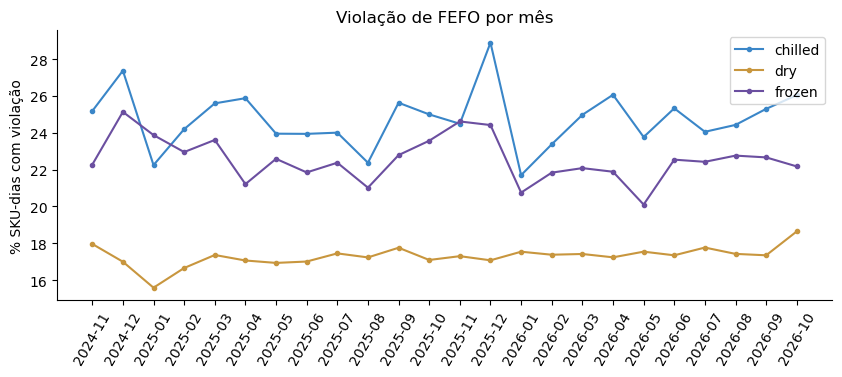

In [3]:
# Linha mensal: mostra se a violação é crônica (constante) ou pontual.
sku_dia["mes"] = sku_dia.date_key.str[:7]
fefo_mes = sku_dia.pivot_table(index="mes", columns="zone", values="violacao", aggfunc="mean").mul(100)
fig, ax = plt.subplots(figsize=(10, 3.5))
for z in fefo_mes:
    ax.plot(fefo_mes.index, fefo_mes[z], marker="o", ms=3, label=z, color=ZONE_COLORS[z])
ax.set_ylabel("% SKU-dias com violação"); ax.set_title("Violação de FEFO por mês"); ax.legend()
ax.tick_params(axis="x", rotation=60)
savefig(fig, "04e_fefo_mensal")

**Leitura:** a violação é **crônica e espalhada** pelo período — não é evento pontual, é método de
trabalho (separador pega o palete mais acessível, não o de validade mais curta). Consequência:
lotes antigos ficam para trás e vencem (ver seção 2). Ação: endereço de picking indicado pelo WMS por
lote/validade, conferência por leitura do lote e auditoria amostral semanal.

## 2. Perdas por vencimento (histórico)

In [4]:
venc = q("""SELECT substr(m.date_key, 1, 7) AS mes, s.zone, SUM(m.qty_units) AS und,
                   SUM(m.qty_units * s.unit_cost) AS custo
            FROM fact_movement m JOIN dim_sku s ON s.sku_id = m.sku_id
            WHERE m.movement_type = 'WRITE_OFF_EXPIRY' GROUP BY 1, 2""")
venc.pivot_table(index="zone", values=["und", "custo"], aggfunc="sum").round(0)

,custo,und
zone,,
chilled,451223.0,65071
dry,120312.0,16350


### 2.1 De onde vêm os lotes que vencem?
Hipótese: lotes que **já chegaram** com pouca vida útil (aceitos abaixo dos 70%, ver 04a) são os
que vencem no estoque.

In [5]:
origem = q("""
    WITH baixa AS (SELECT lot_id, SUM(qty_units) AS und FROM fact_movement
                   WHERE movement_type = 'WRITE_OFF_EXPIRY' GROUP BY lot_id),
         receb AS (SELECT lot_id, AVG(remaining_life_pct) AS vida FROM fact_receipt
                   WHERE status = 'ACCEPTED' GROUP BY lot_id)
    SELECT CASE WHEN r.vida < 70 THEN 'aceito com vida < 70%' ELSE 'aceito com vida >= 70%' END AS grupo,
           COUNT(*) AS lotes_total,
           SUM(b.lot_id IS NOT NULL) AS lotes_que_venceram,
           COALESCE(SUM(b.und), 0) AS und_vencidas
    FROM receb r LEFT JOIN baixa b ON b.lot_id = r.lot_id
    GROUP BY 1""")
origem["pct_lotes_que_venceram"] = (100 * origem.lotes_que_venceram / origem.lotes_total).round(2)
origem["pct_das_und_vencidas"] = (100 * origem.und_vencidas / origem.und_vencidas.sum()).round(1)
origem

,grupo,lotes_total,lotes_que_venceram,und_vencidas,pct_lotes_que_venceram,pct_das_und_vencidas
0,aceito com vida < 70%,2511,74,57857,2.95,72.4
1,aceito com vida >= 70%,59147,150,22054,0.25,27.6


**Leitura:** os lotes aceitos abaixo de 70% de vida útil são uma minoria dos lotes recebidos, mas
respondem pela **maior parte das unidades vencidas**. Ou seja, a perda por vencimento nasce no
**recebimento** (regra de 70% não aplicada para alguns fornecedores, ver 04b), e o FEFO violado agrava.

## 3. Risco de vencimento no último dia da base (visão para a frente)
Para cada lote em estoque: dias até chegar à vida mínima de venda × demanda média diária do SKU
(últimos 90 dias). Consumindo os lotes em ordem FEFO, o que **não** cabe nessa janela é estoque em
risco. *Estimativa:* assume demanda futura = média dos últimos 90 dias.

In [6]:
ultimo = q("SELECT MAX(date_key) AS d FROM fact_inventory_daily").d[0]
est = q("""SELECT i.sku_id, i.lot_id, i.qty_units, l.expiry_date
           FROM fact_inventory_daily i JOIN dim_lot l ON l.lot_id = i.lot_id
           WHERE i.date_key = :d AND i.qty_units > 0""", d=ultimo)
dem90 = q("""SELECT sku_id, SUM(qty_ordered_units) / 90.0 AS d_media
             FROM fact_order_line WHERE order_date > date(:d, '-90 day') GROUP BY sku_id""", d=ultimo)
est = est.merge(sku, on="sku_id").merge(dem90, on="sku_id", how="left").fillna({"d_media": 0})
est["dias_ate_min_venda"] = ((pd.to_datetime(est.expiry_date) - pd.Timestamp(ultimo)).dt.days
                             - est.min_sale_days)
# Ordem FEFO dentro do SKU: o que vence primeiro é vendido primeiro
est = est.sort_values(["sku_id", "expiry_date"])
est["acumulado"] = est.groupby("sku_id").qty_units.cumsum()
# Capacidade de venda até cada lote chegar ao limite: demanda diária x dias disponíveis
est["vende_ate_limite"] = (est.d_media * est.dias_ate_min_venda.clip(lower=0))
est["und_em_risco"] = np.minimum(est.qty_units,
                                 (est.acumulado - est.vende_ate_limite).clip(lower=0))
est["ja_invendavel"] = est.dias_ate_min_venda < 0
est["valor_risco"] = est.und_em_risco * est.unit_cost
est["valor_total"] = est.qty_units * est.unit_cost

risco = est.groupby("zone").agg(valor_estoque=("valor_total", "sum"), valor_em_risco=("valor_risco", "sum"),
                                lotes_ja_invendaveis=("ja_invendavel", "sum"))
risco["pct_em_risco"] = (100 * risco.valor_em_risco / risco.valor_estoque).round(1)
print(f"Foto de {ultimo}:")
risco.round(0)

Foto de 2026-10-31:


,valor_estoque,valor_em_risco,lotes_ja_invendaveis,pct_em_risco
zone,,,,
chilled,616661.0,0.0,0,0.0
dry,1469716.0,5819.0,0,0.0
frozen,428217.0,0.0,0,0.0


In [7]:
top_risco = (est[est.und_em_risco > 0].groupby(["sku_code", "zone", "status"])
             .agg(und_estoque=("qty_units", "sum"), und_em_risco=("und_em_risco", "sum"),
                  valor_em_risco=("valor_risco", "sum"), demanda_dia=("d_media", "first"))
             .sort_values("valor_em_risco", ascending=False).head(15).round(1))
save(est[est.und_em_risco > 0][["sku_id", "sku_code", "zone", "status", "lot_id", "expiry_date",
                                "qty_units", "d_media", "dias_ate_min_venda", "und_em_risco",
                                "valor_risco"]].round(2), "expiry_risk_lots")
top_risco

,,,und_estoque,und_em_risco,valor_em_risco,demanda_dia
sku_code,zone,status,,,,
SKU000340,dry,DISCONTINUED,960,960.0,5443.2,0.0
SKU000136,dry,DISCONTINUED,78,78.0,376.0,0.0


## 4. Estoque parado e descontinuados

In [8]:
ultima_venda = q("""SELECT sku_id, MAX(order_date) AS ultima_venda FROM fact_order_line
                    WHERE qty_picked_units > 0 GROUP BY sku_id""")
parado = (est.groupby("sku_id").agg(und=("qty_units", "sum"), valor=("valor_total", "sum"),
                                    d_media=("d_media", "first"))
          .reset_index().merge(sku, on="sku_id").merge(ultima_venda, on="sku_id", how="left"))
parado["dias_sem_venda"] = (pd.Timestamp(ultimo) - pd.to_datetime(parado.ultima_venda)).dt.days
parado["cobertura_dias"] = np.where(parado.d_media > 0, parado.und / parado.d_media.replace(0, np.nan), np.inf)
parado["categoria_parado"] = np.select(
    [parado.status == "DISCONTINUED", parado.dias_sem_venda > 90, parado.cobertura_dias > 180],
    ["descontinuado com estoque", "sem venda há > 90 dias", "cobertura > 180 dias"], "normal")
resumo_parado = (parado[parado.categoria_parado != "normal"]
                 .groupby(["categoria_parado", "zone"])
                 .agg(skus=("sku_id", "size"), unidades=("und", "sum"), valor_custo=("valor", "sum"))
                 .round(0))
print(f"Valor total em estoque em {ultimo}: R$ {parado.valor.sum():,.0f}")
print(f"Parado/excesso: R$ {resumo_parado.valor_custo.sum():,.0f} "
      f"({resumo_parado.valor_custo.sum() / parado.valor.sum():.1%} do estoque)")
resumo_parado

Valor total em estoque em 2026-10-31: R$ 2,514,595
Parado/excesso: R$ 5,819 (0.2% do estoque)


,,skus,unidades,valor_custo
categoria_parado,zone,,,
descontinuado com estoque,dry,2,1038,5819.0


In [9]:
# Detalhe dos descontinuados: há quanto tempo foram descontinuados e quanto ocupam
desc = parado[parado.status == "DISCONTINUED"][["sku_code", "zone", "category", "discontinued_date",
                                                 "und", "valor", "shelf_life_days", "dias_sem_venda"]]
save(parado[parado.categoria_parado != "normal"].round(2), "dead_slow_stock")
desc.sort_values("valor", ascending=False).round(0)

,sku_code,zone,category,discontinued_date,und,valor,shelf_life_days,dias_sem_venda
282,SKU000340,dry,Higiene e Limpeza,2025-10-14,960,5443.0,720,383
116,SKU000136,dry,Higiene e Limpeza,2025-02-12,78,376.0,1080,627


POs emitidos para SKUs já descontinuados: 0


,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
mes,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,...,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
skus,18,15,18,18,13,18,16,17,17,16,...,10,9,9,7,6,4,3,2,2,2
paletes,54,31,45,47,38,51,47,43,43,39,...,26,24,19,13,11,8,6,5,5,5
valor_custo,104684.0,68840.0,97278.0,107246.0,91873.0,119108.0,102578.0,91686.0,97962.0,87622.0,...,45854.0,38349.0,20640.0,10871.0,9868.0,8589.0,7080.0,5819.0,5819.0,5819.0


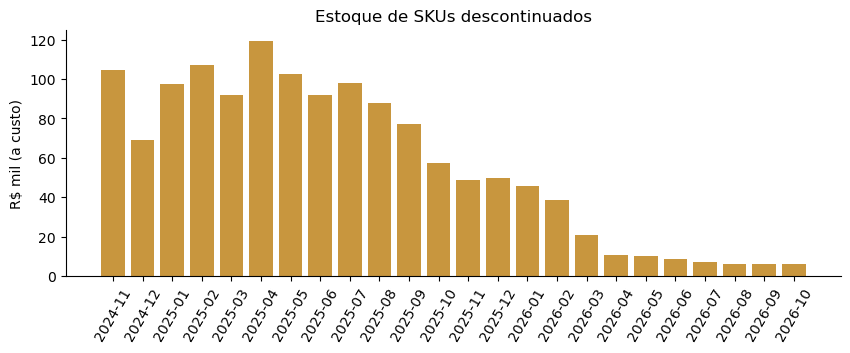

In [10]:
# Evolução do estoque de SKUs descontinuados ao longo do período (foto do dia 28 de cada mês)
desc_mes = q("""SELECT substr(i.date_key, 1, 7) AS mes, COUNT(DISTINCT i.sku_id) AS skus,
                       SUM(i.n_pallets) AS paletes, SUM(i.qty_units * s.unit_cost) AS valor_custo
                FROM fact_inventory_daily i JOIN dim_sku s ON s.sku_id = i.sku_id
                WHERE s.status = 'DISCONTINUED' AND substr(i.date_key, 9, 2) = '28'
                GROUP BY 1""")
# Barras: estoque parado mês a mês (quantidade discreta por período).
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(desc_mes.mes, desc_mes.valor_custo / 1000, color="#C8963E")
ax.set_ylabel("R$ mil (a custo)"); ax.set_title("Estoque de SKUs descontinuados")
ax.tick_params(axis="x", rotation=60)
savefig(fig, "04e_descontinuados_mes")
compras_pos = q("""SELECT COUNT(*) AS pos_apos_descontinuar FROM fact_purchase_order po
                   JOIN dim_sku s ON s.sku_id = po.sku_id
                   WHERE s.status = 'DISCONTINUED' AND po.order_date > s.discontinued_date""")
print("POs emitidos para SKUs já descontinuados:", int(compras_pos.iloc[0, 0]))
desc_mes.round(0).T

**Leitura:**
- **Descontinuados:** os 18 SKUs descontinuados (secos, validade longa, descontinuados entre out/2024
  e nov/2025) somavam ~R$ 100 mil a custo e ~50 paletes parados (escala 10%) e **levaram ~18 meses**
  para escoar — ainda sobram 2 SKUs. Não houve compra depois da descontinuação: o problema é a
  falta de liquidação ativa, não compra indevida. Como a validade é longa, eles **não vencem** e nunca aparecem nas baixas
  por vencimento: passam despercebidos. Ação: liquidação ativa logo na descontinuação (desconto,
  devolução ao fornecedor) e liberação das posições no seco, que bate 100% no pico.
- **Risco de vencimento na foto final:** baixo (o estoque atual tem validade folgada para o giro).
  O risco **histórico** é o da seção 2: perdas concentradas no resfriado, vindas de lotes recebidos
  abaixo de 70% de vida útil, agravadas pelo FEFO violado.

## 5W2H
| O quê | Por quê | Onde | Quem | Quando | Como | Quanto |
|---|---|---|---|---|---|---|
| Separação dirigida por lote (FEFO no WMS) | FEFO violado de forma crônica | Separação | TI WMS + Operações | 60 dias | WMS indica lote; leitura obrigatória do lote | Configuração |
| Rotina semanal de risco de vencimento | Antecipar ação comercial antes do vencimento | Planejamento | PCP + Comercial | Semanal | Relatório `expiry_risk_lots` → promoção/transferência | Zero |
| Liquidação de descontinuados | Capital e posições presos | Seco | Comercial + Compras | 30 dias | Venda com desconto, devolução, doação | Recupera parte do custo |

In [11]:
log(NB, f"FEFO em {len(sku_dia):,} SKU-dias (estoque do dia anterior; lote vendável = "
        f"dias restantes >= min_sale_days); risco de vencimento em {ultimo} (demanda média 90 d); "
        f"estoque parado (descontinuado / >90 d sem venda / cobertura >180 d)")